<a href="https://colab.research.google.com/github/JiaXin-18/data-science-toolkit/blob/main/Data_Science_Tutorial_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Heart_Disease_Prediction.csv")

display(df.head())

,index,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


2. Evaluate if the data is good or not. Does it have enough samples?

In [4]:
print("Rows and columns:",df.shape)
print("Repeated index values:", df["index"].duplicated().sum())
print("Heart Disease values (Absence = No, Presence = Yes):")
print(df["Heart Disease"].value_counts())

Rows and columns: (270, 15)
Repeated index values: 0
Heart Disease values (Absence = No, Presence = Yes):
Heart Disease
Absence     150
Presence    120
Name: count, dtype: int64


3. How many features does it have? Is it enough?

In [5]:
print("All columns:")
print(df.columns.tolist())
print("Number of columns:", len(df.columns))
print("Possible input column (excluding Absence):", len(df.columns)-1)

All columns:
['index', 'Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']
Number of columns: 15
Possible input column (excluding Absence): 14


4. How many samples/observation does it have? Is it enough?

In [7]:
print("Number of patient:", len(df))

Number of patient: 270


5. What are the datatypes does the dataset consist of?

In [8]:
print(df.dtypes)

index                        int64
Age                          int64
Sex                          int64
Chest pain type              int64
BP                           int64
Cholesterol                  int64
FBS over 120                 int64
EKG results                  int64
Max HR                       int64
Exercise angina              int64
ST depression              float64
Slope of ST                  int64
Number of vessels fluro      int64
Thallium                     int64
Heart Disease               object
dtype: object


6 and 8. Which columns and rows have missing (null) values?

In [10]:
missing = df.isnull().sum()
print("Missing values in each column:")
print(missing)
print("\nColumns with missing values:")
print(missing[missing>0])
print("\nNumber of columns with missing values:", (missing>0).sum())

Missing values in each column:
index                      0
Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64

Columns with missing values:
Series([], dtype: int64)

Number of columns with missing values: 0


In [13]:
#aixs 1 = means u are checking the code one by one
#axis 0 = means going down the columns
rows_missing = df[df.isnull().any(axis=1)]
print("Number of rows with least missing value:", len(rows_missing))
print("First 10 rows containing missing values:")
display(rows_missing.head(10))

#to find exact position ofone particular column:
column_to_check = "Age"
print("Missing index:", column_to_check, ":")
print(df.loc[df[column_to_check].isnull(),"index"].tolist())

Number of rows with least missing value: 0
First 10 rows containing missing values:


,index,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease


Missing index: Age :
[]


7. Which column is the feature, which is the target output?

In [15]:
target = "Heart Disease"
features = df.drop(columns=["Heart Disease", "index"])

print("Target:", target)
print("Example feature columns:", features.columns.tolist())
print("Target values:", df[target].unique())

Target: Heart Disease
Example feature columns: ['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium']
Target values: ['Presence' 'Absence']


9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

Heart Disease percentage by sex:
Sex
0    23.0
1    54.6
Name: Heart Disease Binary, dtype: float64


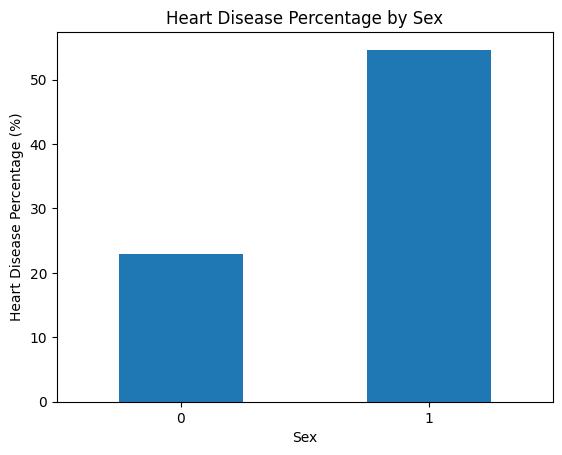

In [19]:
import matplotlib.pyplot as plt

df["Heart Disease Binary"] = df["Heart Disease"].map({
    "Absence": 0,
    "Presence": 1
})

# Calculate heart disease percentage by sex
heart_disease_rate = df.groupby("Sex")["Heart Disease Binary"].mean() * 100

print("Heart Disease percentage by sex:")
print(heart_disease_rate.round(1))

heart_disease_rate.plot(kind="bar")
plt.title("Heart Disease Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Heart Disease Percentage (%)")
plt.xticks(rotation=0)
plt.show()